# Sparse inverse covariance estimation (GraphicalLassoCV): scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/covariance/plot_sparse_cov.py`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/covariance/plot_sparse_cov.html))
at scikit-learn `4358542a1bd39af2e7e1cbace8b9fed067473c5b`.

**Scenario:** 60 standardized samples of 20 features drawn from a sparse-precision Gaussian
(`make_sparse_spd_matrix`, `RandomState(1)`). `GraphicalLassoCV()` (default 4-point grid, 4 refinements, 5-fold `KFold`)
selects `alpha_`; its `covariance_`/`precision_` are compared with `ledoit_wolf` and the empirical estimate, and the
model-selection curve `cv_results_["alphas"]` / `["mean_test_score"]` is plotted.

**Beyond the gallery:** `GraphicalLasso(alpha=alpha_)` with `mode="cd"` and `mode="lars"`, `covariance="precomputed"`,
the `graphical_lasso` function (costs and iteration counts), `cv_results_["std_test_score"]` and the per-split scores,
`costs_`/`n_iter_`, `score`, `GraphicalLassoCV(alphas=[...], mode="lars")` with an explicit grid, and keyword
`set_params` + refit.

**Adaptations:**
- The data (`make_sparse_spd_matrix`, `multivariate_normal`, standardization) is generated by the official code in
  Python and shared; `make_sparse_spd_matrix` belongs to `sklearn.datasets`, not to this family.
- `cv_results_` is a typed record (`alphas`, `mean_test_score`, `std_test_score`, `split_test_score` matrix of shape
  `(n_alphas, n_splits)`) instead of a dictionary with `split{k}_test_score` keys; `graphical_lasso` returns a record
  with covariance, precision, costs and n_iter always present instead of `return_costs`/`return_n_iter` tuples
  (`families/covariance/algorithms/graphical/docs/api.md`).
- `linalg.inv` of the empirical and Ledoit-Wolf covariances is plotting-only reference code and stays in Python.

**Determinism:** deterministic (closed-form data, unshuffled folds, deterministic coordinate descent).

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("covariance/plot_sparse_cov")

## 1. scikit-learn (Python reference)

The official example code (one combined small figure).

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import linalg
from sklearn.datasets import make_sparse_spd_matrix
from sklearn.covariance import GraphicalLassoCV, ledoit_wolf

n_samples = 60
n_features = 20
prng = np.random.RandomState(1)
prec = make_sparse_spd_matrix(n_features, alpha=0.98, smallest_coef=0.4, largest_coef=0.7, random_state=prng)
cov = linalg.inv(prec)
d = np.sqrt(np.diag(cov))
cov /= d
cov /= d[:, np.newaxis]
prec *= d
prec *= d[:, np.newaxis]
X = prng.multivariate_normal(np.zeros(n_features), cov, size=n_samples)
X -= X.mean(axis=0)
X /= X.std(axis=0)

emp_cov = np.dot(X.T, X) / n_samples
model = GraphicalLassoCV()
model.fit(X)
cov_ = model.covariance_
prec_ = model.precision_
lw_cov_, _ = ledoit_wolf(X)
lw_prec_ = linalg.inv(lw_cov_)
print("alpha_ = %.6f, n_iter_ = %d" % (model.alpha_, model.n_iter_))

alpha_ = 0.263501, n_iter_ = 2


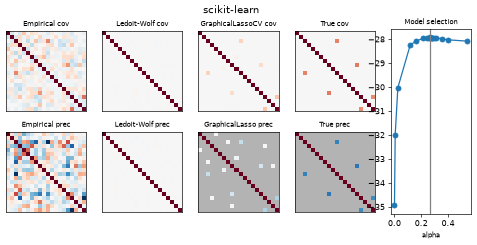

In [3]:
def panels(title, cov_, prec_, lw_cov_, lw_prec_, alphas, scores, alpha_):
    fig = plt.figure(figsize=(10, 4), dpi=60)
    fig.suptitle(title)
    covs = [("Empirical", emp_cov), ("Ledoit-Wolf", lw_cov_), ("GraphicalLassoCV", cov_), ("True", cov)]
    vmax = cov_.max()
    for i, (name, this_cov) in enumerate(covs):
        ax = fig.add_subplot(2, 5, i + 1)
        ax.imshow(this_cov, interpolation="nearest", vmin=-vmax, vmax=vmax, cmap=plt.cm.RdBu_r)
        ax.set_xticks(()); ax.set_yticks(()); ax.set_title("%s cov" % name, fontsize=8)
    precs = [("Empirical", linalg.inv(emp_cov)), ("Ledoit-Wolf", lw_prec_), ("GraphicalLasso", prec_), ("True", prec)]
    vmax = 0.9 * prec_.max()
    for i, (name, this_prec) in enumerate(precs):
        ax = fig.add_subplot(2, 5, i + 6)
        ax.imshow(np.ma.masked_equal(this_prec, 0), interpolation="nearest", vmin=-vmax, vmax=vmax, cmap=plt.cm.RdBu_r)
        ax.set_xticks(()); ax.set_yticks(()); ax.set_title("%s prec" % name, fontsize=8); ax.set_facecolor(".7")
    ax = fig.add_subplot(1, 5, 5)
    ax.plot(alphas, scores, "o-"); ax.axvline(alpha_, color=".5"); ax.set_title("Model selection", fontsize=8)
    ax.set_xlabel("alpha", fontsize=8)
    plt.show()

panels("scikit-learn", cov_, prec_, lw_cov_, lw_prec_, model.cv_results_["alphas"], model.cv_results_["mean_test_score"], model.alpha_)

Fixed-alpha solvers, the functional form, explicit grids and parameter updates beyond the gallery.

In [4]:
from sklearn.covariance import GraphicalLasso, graphical_lasso
extra = {}
res = model.cv_results_
n_splits = 5
extra["cv_alphas"], extra["cv_mean"], extra["cv_std"] = res["alphas"], res["mean_test_score"], res["std_test_score"]
extra["cv_split"] = np.column_stack([res["split%d_test_score" % k] for k in range(n_splits)])
extra["cv_costs"] = np.array(model.costs_)
extra["cv_scalars"] = np.array([model.alpha_, model.n_iter_, model.score(X)])
extra["lw_cov"], extra["location"] = lw_cov_, model.location_
alpha = model.alpha_
for mode in ("cd", "lars"):
    g = GraphicalLasso(alpha=alpha, mode=mode).fit(X)
    extra[mode + "_cov"], extra[mode + "_prec"] = g.covariance_, g.precision_
    extra[mode + "_costs"] = np.array(g.costs_)
    extra[mode + "_scalars"] = np.array([g.n_iter_, g.score(X)])
pre = GraphicalLasso(alpha=0.2, covariance="precomputed").fit(emp_cov)
extra["pre_prec"] = pre.precision_
c, p, costs, n_iter = graphical_lasso(emp_cov, 0.1, mode="lars", return_costs=True, return_n_iter=True)
extra.update(fn_cov=c, fn_prec=p, fn_costs=np.array(costs), fn_n_iter=np.array([n_iter]))
explicit = GraphicalLassoCV(alphas=[0.5, 0.2, 0.05, 0.01], mode="lars").fit(X)
extra["ex_alphas"], extra["ex_mean"] = explicit.cv_results_["alphas"], explicit.cv_results_["mean_test_score"]
extra["ex_alpha"] = np.array([explicit.alpha_])
g = GraphicalLasso(alpha=0.3).fit(X)
g.set_params(alpha=0.05, tol=1e-6, max_iter=200)
g.fit(X)
extra["sp_prec"], extra["sp_n_iter"] = g.precision_, np.array([g.n_iter_])
print("precision condition number:", np.linalg.cond(prec_), "| sparsity (zeros):", int(np.sum(prec_ == 0)))
nb.share(X=X, emp_cov=emp_cov)

precision condition number: 1.7792548321107136 | sparsity (zeros): 364


/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/numpy/_core/_methods.py:188: RuntimeWarning: invalid value encountered in subtract
  x = um.subtract(arr, arrmean, out=...)
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/covariance/_graph_lasso.py:197: ConvergenceWarning: graphical_lasso: did not converge after 200 iteration: dual gap: 1.373e-04
  warnings.warn(


## 2. Moxie (native Mojo)

In [5]:
%%mojo graphical
from numojo import NDArray, Shape
from moxie.covariance import GraphicalLasso, GraphicalLassoCV, graphical_lasso, ledoit_wolf
from moxie_nb_io import load, save, save_floats, save_ints


def costs(values: List[Tuple[Float64, Float64]]) raises -> NDArray[DType.float64]:
    var out = NDArray[DType.float64](Shape(len(values), 2))
    for i in range(len(values)):
        out.unsafe_set(2 * i, values[i][0])
        out.unsafe_set(2 * i + 1, values[i][1])
    return out^


def main() raises:
    var X = load("X")
    var emp_cov = load("emp_cov")
    var model = GraphicalLassoCV()
    _ = model.fit(X)
    save("cov_", model.covariance_())
    save("prec_", model.precision_().value())
    save("location", model.location_())
    var res = model.cv_results_()
    save("cv_alphas", res.alphas)
    save("cv_mean", res.mean_test_score)
    save("cv_std", res.std_test_score)
    save("cv_split", res.split_test_score)
    save("cv_costs", costs(model.costs_()))
    save_floats("cv_scalars", [model.alpha_(), Float64(model.n_iter_()), model.score(X)])
    var lw = ledoit_wolf(X)
    save("lw_cov", lw[0])
    print("alpha_ =", model.alpha_(), " n_iter_ =", model.n_iter_())

    var alpha = model.alpha_()
    for mode in ["cd", "lars"]:
        var g = GraphicalLasso(alpha=alpha, mode=String(mode))
        _ = g.fit(X)
        save(String(mode) + "_cov", g.covariance_())
        save(String(mode) + "_prec", g.precision_().value())
        save(String(mode) + "_costs", costs(g.costs_()))
        save_floats(String(mode) + "_scalars", [Float64(g.n_iter_()), g.score(X)])
    var pre = GraphicalLasso(alpha=0.2, covariance=String("precomputed"))
    _ = pre.fit(emp_cov)
    save("pre_prec", pre.precision_().value())
    var result = graphical_lasso(emp_cov, 0.1, mode="lars")
    save("fn_cov", result.covariance)
    save("fn_prec", result.precision)
    save("fn_costs", costs(result.costs))
    save_ints("fn_n_iter", [result.n_iter])
    var grid = List[Float64]()
    grid.append(0.5)
    grid.append(0.2)
    grid.append(0.05)
    grid.append(0.01)
    var explicit = GraphicalLassoCV(alphas=grid^, mode="lars")
    _ = explicit.fit(X)
    save("ex_alphas", explicit.cv_results_().alphas)
    save("ex_mean", explicit.cv_results_().mean_test_score)
    save_floats("ex_alpha", [explicit.alpha_()])
    var g = GraphicalLasso(alpha=0.3)
    _ = g.fit(X)
    _ = g.set_params(alpha=0.05, tol=1e-6, max_iter=200)
    _ = g.fit(X)
    save("sp_prec", g.precision_().value())
    save_ints("sp_n_iter", [g.n_iter_()])

alpha_ = 0.26350120881905115  n_iter_ = 2


## 3. Side by side and parity

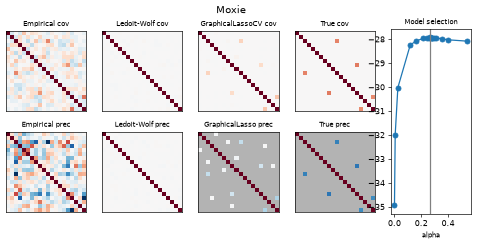

/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/notebooks/_support/moxie_nb.py:141: RuntimeWarning: invalid value encountered in subtract
  diff = np.abs(sk64 - mx64)


check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
GraphicalLassoCV alpha_,PASS,(),(),0,0,"rtol=1e-12, atol=0",,grid point chosen by argmax of mean scores; refined grids are geometric sequences in Float64
GraphicalLassoCV n_iter_,PASS,"(1,)","(1,)",,,exact,0 mismatches,
GraphicalLassoCV score(X),PASS,"(1,)","(1,)",3.2e-14,1.14e-15,"rtol=1e-10, atol=0",,same Float64 CD/LARS updates; roundoff (BLAS vs native dot order) amplified over the solver iterations
GraphicalLassoCV covariance_,PASS,"(20, 20)","(20, 20)",5.73e-14,4.16e-13,"rtol=0, atol=1e-10",,same Float64 CD/LARS updates; roundoff (BLAS vs native dot order) amplified over the solver iterations
GraphicalLassoCV precision_,PASS,"(20, 20)","(20, 20)",6.76e-14,2.23e-13,"rtol=0, atol=1e-09",,same Float64 CD/LARS updates; roundoff (BLAS vs native dot order) amplified over the solver iterations; precision entries up to ~2
GraphicalLassoCV precision_ sparsity pattern,PASS,"(20, 20)","(20, 20)",,,exact,0 mismatches,
GraphicalLassoCV location_,PASS,"(20,)","(20,)",0,0,"rtol=0, atol=1e-15",,means of standardized data (~1e-17)
cv_results_ alphas,PASS,"(17,)","(17,)",1.11e-16,2.04e-16,"rtol=1e-12, atol=0",,Float64 geometric grids
cv_results_ mean_test_score,PASS,"(17,)","(17,)",1.85e-10,6.63e-12,"rtol=1e-09, atol=0",,same Float64 CD/LARS updates; roundoff (BLAS vs native dot order) amplified over the solver iterations per fold path
cv_results_ std_test_score,PASS,"(17,)","(17,)",1.03e-10,1.35e-10,"rtol=1e-07, atol=1e-10",,standard deviation of 5 fold scores agreeing to ~1e-10: relative error of a small spread is larger


In [6]:
mx = nb.results["graphical"]
panels("Moxie", mx["cov_"], mx["prec_"], mx["lw_cov"], linalg.inv(mx["lw_cov"]), mx["cv_alphas"], mx["cv_mean"], mx["cv_scalars"][0])
moxie_nb.side_by_side(sklearn=dict(alpha_=model.alpha_, n_iter_=model.n_iter_), moxie=dict(alpha_=mx["cv_scalars"][0], n_iter_=int(mx["cv_scalars"][1])))
# Coordinate descent stops at tol=1e-4 on the dual gap, so iterates are only defined up to the same sequence of
# floating-point updates: identical algorithms (Gram CD / LARS ports, Float64) agree to roundoff amplified by the
# iteration count and the precision's condition number (printed above).
GL = "same Float64 CD/LARS updates; roundoff (BLAS vs native dot order) amplified over the solver iterations"
nb.compare("GraphicalLassoCV alpha_", model.alpha_, mx["cv_scalars"][0], rtol=1e-12, atol=0,
           reason="grid point chosen by argmax of mean scores; refined grids are geometric sequences in Float64")
nb.compare("GraphicalLassoCV n_iter_", extra["cv_scalars"][1:2], mx["cv_scalars"][1:2], exact=True)
nb.compare("GraphicalLassoCV score(X)", extra["cv_scalars"][2:], mx["cv_scalars"][2:], rtol=1e-10, atol=0, reason=GL)
nb.compare("GraphicalLassoCV covariance_", cov_, mx["cov_"], rtol=0, atol=1e-10, reason=GL)
nb.compare("GraphicalLassoCV precision_", prec_, mx["prec_"], rtol=0, atol=1e-9, reason=GL + "; precision entries up to ~2")
nb.compare("GraphicalLassoCV precision_ sparsity pattern", prec_ == 0, mx["prec_"] == 0, exact=True)
nb.compare("GraphicalLassoCV location_", extra["location"], mx["location"], rtol=0, atol=1e-15, reason="means of standardized data (~1e-17)")
nb.compare("cv_results_ alphas", extra["cv_alphas"], mx["cv_alphas"], rtol=1e-12, atol=0, reason="Float64 geometric grids")
nb.compare("cv_results_ mean_test_score", extra["cv_mean"], mx["cv_mean"], rtol=1e-9, atol=0, reason=GL + " per fold path")
nb.compare("cv_results_ std_test_score", extra["cv_std"], mx["cv_std"], rtol=1e-7, atol=1e-10,
           reason="standard deviation of 5 fold scores agreeing to ~1e-10: relative error of a small spread is larger")
nb.compare("cv_results_ split scores (n_alphas, n_splits)", extra["cv_split"], mx["cv_split"], rtol=1e-9, atol=0, reason=GL)
nb.compare("GraphicalLassoCV costs_ (objective, dual gap)", extra["cv_costs"], mx["cv_costs"], rtol=1e-8, atol=1e-12,
           reason="dual gaps approach 0 near convergence, so an absolute floor is needed")
nb.compare("ledoit_wolf(X) covariance", extra["lw_cov"], mx["lw_cov"], rtol=0, atol=1e-14, reason="closed form; summation order")
for mode in ("cd", "lars"):
    nb.compare(f"GraphicalLasso(alpha_, mode={mode!r}) covariance_", extra[mode + "_cov"], mx[mode + "_cov"], rtol=0, atol=1e-10, reason=GL)
    nb.compare(f"GraphicalLasso(alpha_, mode={mode!r}) precision_", extra[mode + "_prec"], mx[mode + "_prec"], rtol=0, atol=1e-9, reason=GL)
    nb.compare(f"GraphicalLasso(alpha_, mode={mode!r}) costs_", extra[mode + "_costs"], mx[mode + "_costs"], rtol=1e-8, atol=1e-12,
               reason="as for the CV costs")
    nb.compare(f"GraphicalLasso(alpha_, mode={mode!r}) n_iter_, score", extra[mode + "_scalars"], mx[mode + "_scalars"], rtol=1e-10, atol=0, reason=GL)
nb.compare("GraphicalLasso(covariance='precomputed') precision_", extra["pre_prec"], mx["pre_prec"], rtol=0, atol=1e-9, reason=GL)
nb.compare("graphical_lasso(emp_cov, 0.1, mode='lars') covariance", extra["fn_cov"], mx["fn_cov"], rtol=0, atol=1e-10, reason=GL)
nb.compare("graphical_lasso precision", extra["fn_prec"], mx["fn_prec"], rtol=0, atol=1e-9, reason=GL)
nb.compare("graphical_lasso costs", extra["fn_costs"], mx["fn_costs"], rtol=1e-8, atol=1e-12, reason="as for the CV costs")
nb.compare("graphical_lasso n_iter", extra["fn_n_iter"], mx["fn_n_iter"], exact=True)
nb.compare("GraphicalLassoCV(alphas=[...], mode='lars') alphas", extra["ex_alphas"], mx["ex_alphas"], exact=True)
nb.compare("GraphicalLassoCV(alphas=[...], mode='lars') mean_test_score", extra["ex_mean"], mx["ex_mean"], rtol=1e-9, atol=0, reason=GL)
nb.compare("GraphicalLassoCV(alphas=[...], mode='lars') alpha_", extra["ex_alpha"], mx["ex_alpha"], exact=True)
nb.compare("set_params(alpha=0.05, tol=1e-6, max_iter=200) + refit: precision_", extra["sp_prec"], mx["sp_prec"], rtol=0, atol=1e-9, reason=GL)
nb.compare("set_params + refit: n_iter_", extra["sp_n_iter"], mx["sp_n_iter"], exact=True)
nb.note("cv_results_", "ADAPTED", "typed record with a (n_alphas, n_splits) split_test_score matrix instead of split{k}_test_score keys")
nb.note("graphical_lasso return_costs/return_n_iter", "ADAPTED", "record always carries covariance, precision, costs and n_iter")
nb.report()
nb.assert_parity()